# Dataset Cleaning for Players


In [136]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.stats import iqr


players = pd.read_csv("../basketballPlayoffs/players.csv")
print(players.head())
players.shape


        bioID  pos  firstseason  lastseason  height  weight  \
0  abrahta01w    C            0           0    74.0     190   
1  abrossv01w    F            0           0    74.0     169   
2  adairje01w    C            0           0    76.0     197   
3  adamsda01w  F-C            0           0    73.0     239   
4  adamsjo01w    C            0           0    75.0     180   

             college            collegeOther   birthDate   deathDate  
0  George Washington                     NaN  1975-09-27  0000-00-00  
1        Connecticut                     NaN  1980-07-09  0000-00-00  
2  George Washington                     NaN  1986-12-19  0000-00-00  
3          Texas A&M  Jefferson College (JC)  1989-02-19  0000-00-00  
4         New Mexico                     NaN  1981-05-24  0000-00-00  


(893, 10)

# Check For Null Values

In [137]:
null = players.isnull().values.any()
nan = players.isna().values.any()

print(null)
print(nan)

# Missing Values Found! Time to Work on Them

True
True


# Detecting Missing Values

Unique values in 'bioID':
Total unique values in 'bioID': 893

Unique values in 'pos':
Total unique values in 'pos': 8

Unique values in 'firstseason':
Total unique values in 'firstseason': 1

Unique values in 'lastseason':
Total unique values in 'lastseason': 1

Unique values in 'height':
Total unique values in 'height': 21

Unique values in 'weight':
Total unique values in 'weight': 105

Unique values in 'college':
Total unique values in 'college': 161

Unique values in 'collegeOther':
Total unique values in 'collegeOther': 12

Unique values in 'birthDate':
Total unique values in 'birthDate': 764

Unique values in 'deathDate':
Total unique values in 'deathDate': 5



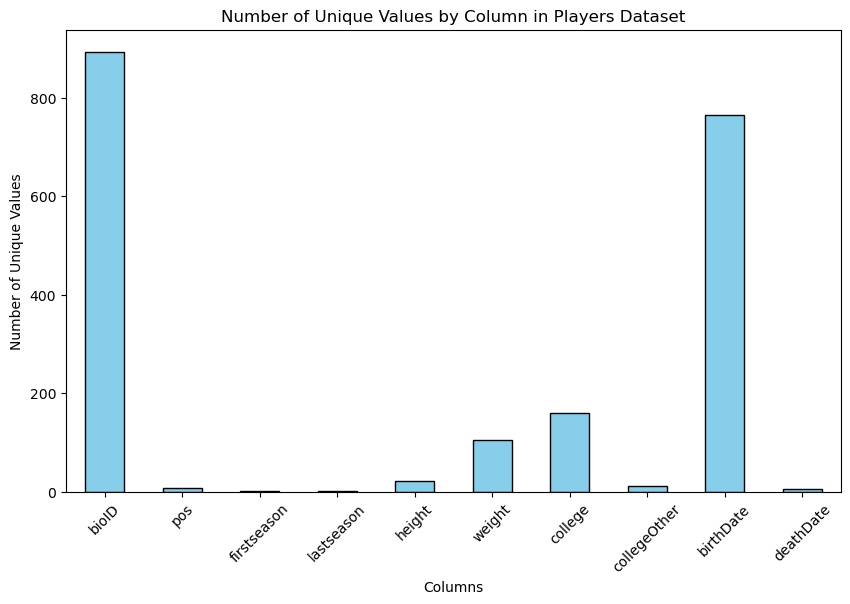

In [138]:
#First lets see how many values in each column
for column in players.columns:
    unique_values = players[column].unique().size
    print(f"Unique values in '{column}':")
    print(f"Total unique values in '{column}': {(unique_values)}\n")

unique_counts = players.nunique()

# Plot unique values as a bar chart
plt.figure(figsize=(10, 6))
unique_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Number of Unique Values by Column in Players Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Unique Values")
plt.xticks(rotation=45)
plt.show()


# Dropping Unique Value Columns

In [139]:
for col in players.columns:
    if players[col].nunique() == 1:
        players.drop(col, inplace=True, axis=1)
print("Remaining columns after dropping single-value columns:")
print(players.columns.tolist())

Remaining columns after dropping single-value columns:
['bioID', 'pos', 'height', 'weight', 'college', 'collegeOther', 'birthDate', 'deathDate']


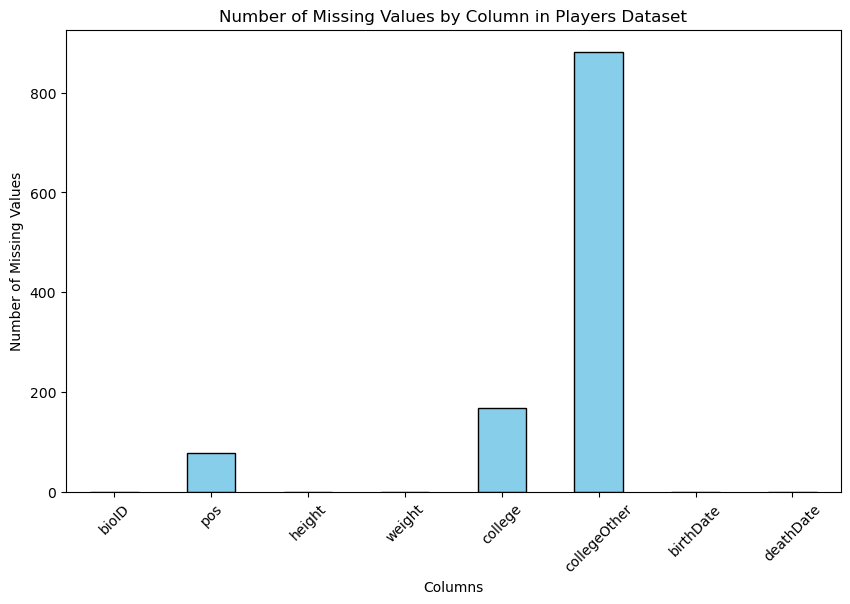

In [140]:
missing_counts = players.isnull().sum()

plt.figure(figsize=(10, 6))
missing_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Number of Missing Values by Column in Players Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.show()





In [141]:
# CollegeOther has a large part of missing values so we think its better to be dropped. Regarding college and position we are making the decision to drop those features aswell
# Because they should not interfere with the final goal of this project.

players.drop(['pos','college','collegeOther'],axis=1,inplace=True)
print(players.columns.tolist(),'\n')

# Regarding the DeathDate we are deciding to remove the players that have a valid deathDate and remove the column.
players = players[(players['deathDate'] == "0000-00-00") | (players['deathDate'].isna())]
players.drop(columns=['deathDate'], inplace=True)
print("Remaining columns after filtering and dropping 'deathDate':")
print(players.columns.tolist())
print(players.shape[0])

['bioID', 'height', 'weight', 'birthDate', 'deathDate'] 

Remaining columns after filtering and dropping 'deathDate':
['bioID', 'height', 'weight', 'birthDate']
889


# Dealing with Redundancy

In [142]:

row_count = players.shape[0]
players.drop_duplicates(inplace=True)
afterDups_count = players.shape[0]
rows_deleted = row_count - afterDups_count
print(f"Number of rows deleted: {rows_deleted}")



Number of rows deleted: 0


# Dealing With Outliers

`# https://www.askpython.com/python/examples/how-to-determine-outlier`

# Z-Score Implementation

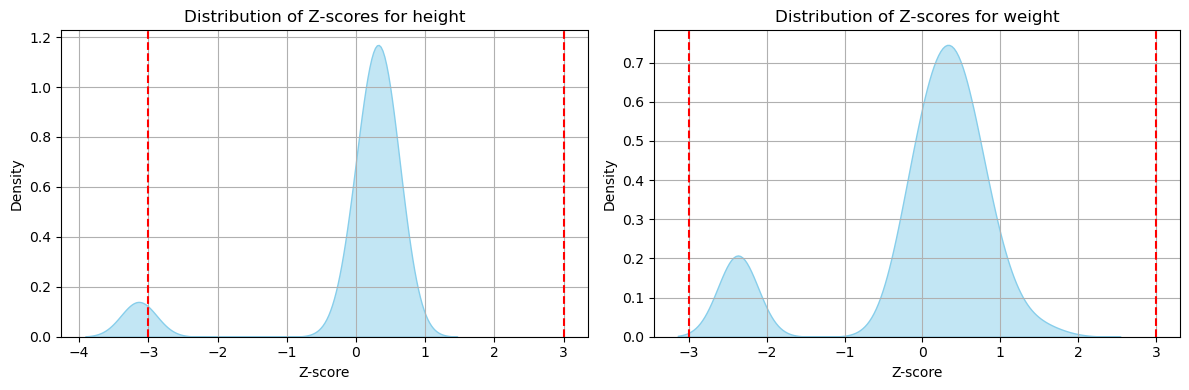

Total number of rows with outliers: 80
Outliers replaced with column means.


In [143]:
numerical_cols = players.select_dtypes(['number'])


z_scores = numerical_cols.apply(zscore)


num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))
axes = axes.flatten()

for i, column in enumerate(numerical_cols.columns):
    sns.kdeplot(z_scores[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution of Z-scores for {column}')
    axes[i].set_xlabel('Z-score')
    axes[i].set_ylabel('Density')
    axes[i].grid(True)
    axes[i].axvline(x=3, color='red', linestyle='--')
    axes[i].axvline(x=-3, color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

outliers = (z_scores > 3) | (z_scores < -3)

outlier_indices = outliers.any(axis=1)
print(f"Total number of rows with outliers: {outlier_indices.sum()}")

for column in numerical_cols.columns:
    mean_value = players[column].mean()  
    players[column] = players[column].where(~outliers[column], mean_value)


changed_rows = players.index[outlier_indices].tolist()
print("Outliers replaced with column means.")


# Interquartile Range Implementation

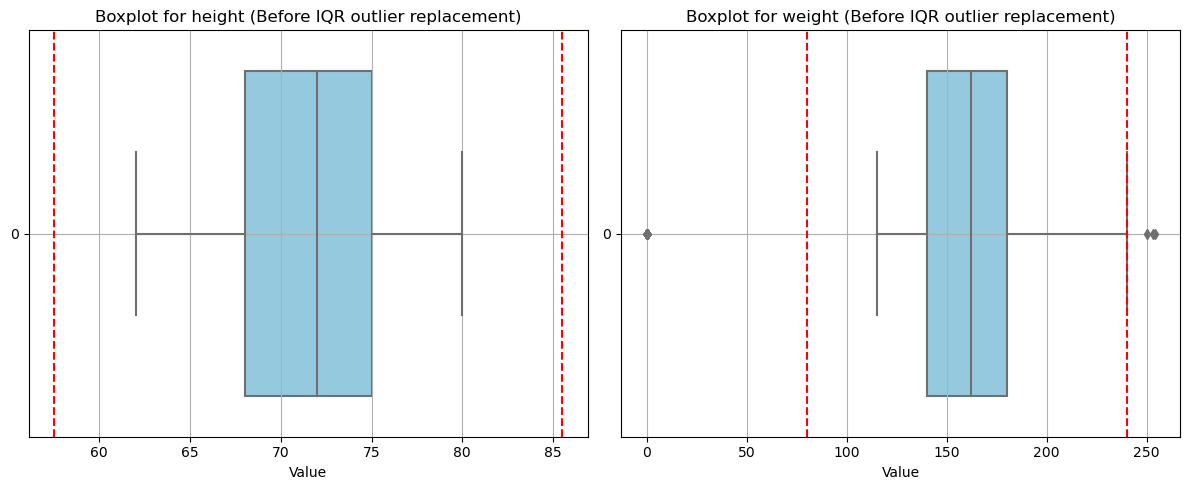

Number of rows changed due to IQR outliers: 122


In [144]:
numerical_cols = players.select_dtypes(include='number')
iqr_values = {}
lower_bounds = {}
upper_bounds = {}
outliers_iqr = pd.DataFrame(False, index=players.index, columns=numerical_cols.columns)

num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_cols.columns):
    sns.boxplot(data=players[column], ax=axes[i], color='skyblue', orient='h')
    axes[i].set_title(f'Boxplot for {column} (Before IQR outlier replacement)')
    axes[i].set_xlabel('Value')
    axes[i].grid(True)
    Q1 = players[column].quantile(0.25)  
    Q3 = players[column].quantile(0.75) 
    column_iqr = iqr(players[column])  
    iqr_values[column] = column_iqr
    lower_bound = Q1 - 1.5 * column_iqr
    upper_bound = Q3 + 1.5 * column_iqr  
    lower_bounds[column] = lower_bound
    upper_bounds[column] = upper_bound
    axes[i].axvline(x=lower_bound, color='red', linestyle='--', label=f'Lower Bound ({lower_bound:.2f})')
    axes[i].axvline(x=upper_bound, color='red', linestyle='--', label=f'Upper Bound ({upper_bound:.2f})')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()
for column in numerical_cols.columns:
    outliers_iqr[column] = (players[column] < lower_bounds[column]) | (players[column] > upper_bounds[column])

for column in numerical_cols.columns:
    mean_value = players[column].mean()  
    players[column] = players[column].where(~outliers_iqr[column], mean_value) 

outlier_indices_iqr = outliers_iqr.any(axis=1)
num_changed_rows_iqr = outlier_indices_iqr.sum()

print(f"Number of rows changed due to IQR outliers: {num_changed_rows_iqr}")



# Create Clean CSV

In [145]:
players['height'] = players['height'].round(1)
players['weight'] = players['weight'].round(1)
players.to_csv('../cleaned_datasets/players_cleaned.csv', index=False)